# Optical pooled screens

An optical pooled screen (OPS) delivers a CRISPR library to one dish of cells, images their morphology, and then
reads each cell's guide by in-situ sequencing. Every well holds thousands of perturbations at once, so the unit of
analysis is no longer the well but the guide, and the well becomes the replicate.

This page analyses a subset of **Aconcagua**, a HeLa screen of 5,299 essential and DepMap-dependency genes imaged in
four channels: DNA (DAPI), microtubules (alpha-tubulin), DNA damage (gamma-H2AX) and F-actin (phalloidin). The cells
were segmented and measured with [brieflow](https://github.com/cheeseman-lab/brieflow). The subset keeps all 250
non-targeting guides, four annotated positive controls, 50 strong and 50 weak known hits, and 396 random library
genes, as profiles of each guide in each of 46 wells.

The story runs from a single cell to a gene call. Along the way it meets three problems that are easy to miss in a
pooled screen: profiles built from different numbers of cells, a calibration that reuses its own controls, and the
DNA damage that Cas9 causes simply by cutting.

The data are from Di Bernardo et al., Nat Commun 17, 6997 (2026), [doi:10.1038/s41467-026-73643-7](https://doi.org/10.1038/s41467-026-73643-7),
originally screened in Funk et al., Cell 185, 4634 (2022), and are available through the CZ Biohub OPS Explorer.

In [1]:
import warnings

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
from scipy.stats import kstest

import mantispy as mt

warnings.filterwarnings("ignore")
sc.settings.verbosity = 0
plt.rcParams["figure.dpi"] = 110
SEED = 0

adata = mt.ds.aconcagua()
adata

AnnData object with n_obs × n_vars = 84125 × 1483
    obs: 'Metadata_Plate', 'Metadata_Well', 'Metadata_Guide', 'Metadata_CellCount', 'Metadata_SiteCount', 'Metadata_Gene', 'Metadata_Perturbation', 'Metadata_Control_Type', 'Metadata_Tier', 'Metadata_Control', 'Metadata_Perturbation_Type', 'Metadata_ObjectType', 'Metadata_MitoticFraction'
    var: 'object', 'feature_group', 'feature', 'channel', 'scale', 'angle', 'gray_levels', 'radial_bin', 'params', 'is_feature', 'feature_kind', 'degenerate_scale'
    uns: 'mantispy'
    layers: None (.X)

One row per guide per well: the median of that guide's cells in that well, normalized against the non-targeting
cells of the same well with {func}`~mantispy.pp.normalize`. Mitotic cells were kept at their natural share, so a
profile pools interphase and mitotic cells as the screen saw them, and each row records its mitotic fraction.

## What the screen sees

Before any profile, a cell. The OPS Explorer publishes example crops of segmented cells, one small OME-Zarr per cell
in four channels. A handful of cells for one gene shows what every feature below is measured from: the nucleus in
DNA, the spindle in tubulin, double-strand breaks in gamma-H2AX, and the cell body in actin.

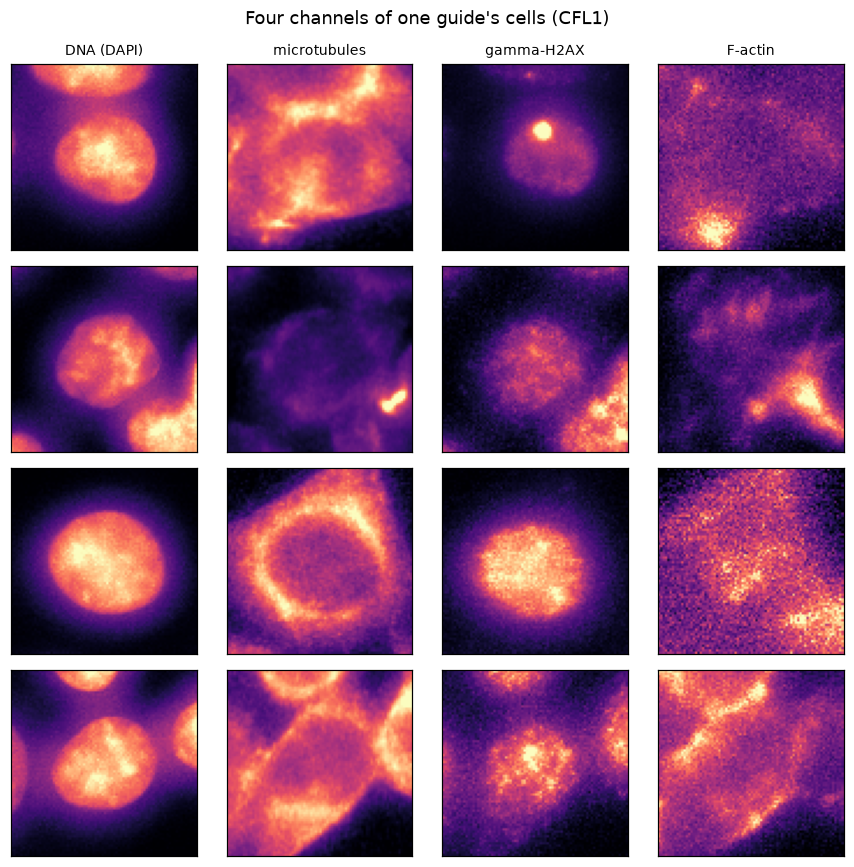

In [2]:
import boto3
import zarr
from botocore import UNSIGNED
from botocore.config import Config

# Example single-cell crops from the OPS Explorer public bucket (anonymous S3). Needs `boto3` and `zarr`.
_S3 = boto3.client("s3", region_name="us-west-2", config=Config(signature_version=UNSIGNED))
_BUCKET = "ops-explorer-public"
_EXAMPLES = "aconcagua/aconcagua/visualizations/interphase/examples/DAPI_TUBULIN_GH2AX_PHALLOIDIN"
CHANNELS = ["DNA (DAPI)", "microtubules", "gamma-H2AX", "F-actin"]
_CROPS = pooch.os_cache("mantispy") / "aconcagua_crops"


def _prefixes(prefix):
    out, token = [], None
    while True:
        extra = {"ContinuationToken": token} if token else {}
        r = _S3.list_objects_v2(Bucket=_BUCKET, Prefix=prefix.rstrip("/") + "/", Delimiter="/", **extra)
        out += [p["Prefix"] for p in r.get("CommonPrefixes", [])]
        if not r.get("IsTruncated"):
            return out
        token = r["NextContinuationToken"]


def example_cells(gene, n=4, seed=SEED):
    """Return n (4, H, W) crops for a gene, downloaded once and cached locally."""
    guide = _prefixes(f"{_EXAMPLES}/{gene}")[0].rstrip("/")
    crops = _prefixes(guide)
    picks = np.random.default_rng(seed).choice(len(crops), size=min(n, len(crops)), replace=False)
    images = []
    for i in sorted(picks):
        crop = crops[i].rstrip("/")
        local = _CROPS / crop
        if not (local / "zarr.json").exists():
            local.mkdir(parents=True, exist_ok=True)
            for obj in _S3.list_objects_v2(Bucket=_BUCKET, Prefix=crop + "/")["Contents"]:
                dst = _CROPS / obj["Key"]
                dst.parent.mkdir(parents=True, exist_ok=True)
                _S3.download_file(_BUCKET, obj["Key"], str(dst))
        images.append(np.asarray(zarr.open_group(str(local), mode="r")["0"][:]).squeeze())
    return images


def _stretch(plane):
    lo, hi = np.percentile(plane, [1, 99.5])
    return np.clip((plane.astype(float) - lo) / max(hi - lo, 1), 0, 1)


def show_cells(images, title):
    """Draw each cell as a row of its four channels."""
    fig, axes = plt.subplots(len(images), 4, figsize=(8, 2 * len(images)), squeeze=False)
    for row, img in enumerate(images):
        for col in range(4):
            ax = axes[row, col]
            ax.imshow(_stretch(img[col]), cmap="magma")
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(CHANNELS[col], fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


show_cells(example_cells("CFL1"), "Four channels of one guide's cells (CFL1)")

Each row is one cell; each column a channel. The features that follow are summaries of images like these: the
intensity in a channel, the texture of the nucleus, the shape of the cell.

## The design

The subset was built to make the analysis legible. Every tier holds a comparable number of profiles, and, crucially,
a comparable number of cells per profile. Controls and targeting guides were matched to about ten cells each.

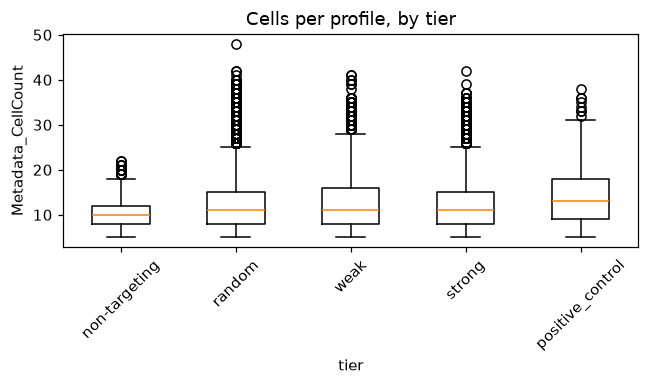

In [3]:
adata.obs["tier"] = np.where(
    adata.obs["Metadata_Control_Type"] == "negcon", "non-targeting", adata.obs["Metadata_Tier"].astype(str)
)
order = ["non-targeting", "positive_control", "strong", "weak", "random"]
adata.obs["tier"] = pd.Categorical(adata.obs["tier"], [t for t in order if t in set(adata.obs["tier"])])
fig, ax = plt.subplots(figsize=(6, 3.6))
mt.pl.cell_counts(adata, groupby="tier", count_key="Metadata_CellCount", ax=ax)
ax.set_title("Cells per profile, by tier")
fig.tight_layout()
plt.show()

## Positive controls move their own channel

Before calling anything, the screen's own positive controls should move the channel they were chosen for. The
knockouts of H2AX, TUBB and CFL1 remove or disturb the very protein a stain detects, so each should shift its
feature away from the non-targeting cells.

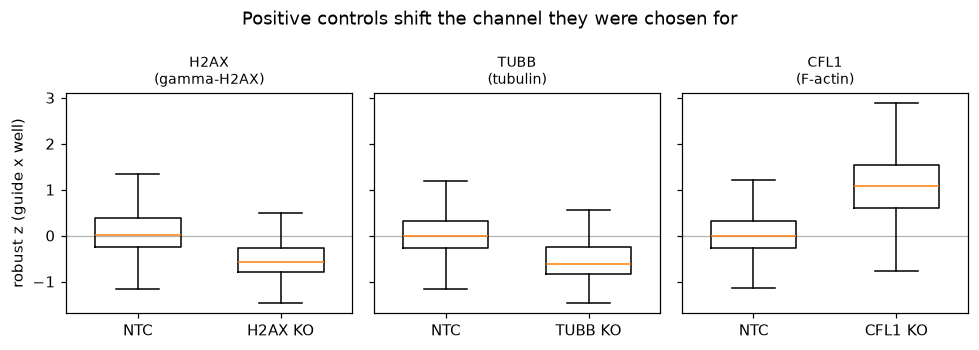

In [4]:
controls = (adata.obs["Metadata_Control_Type"] == "negcon").to_numpy()
checks = {
    "H2AX": ("Nuclei_Intensity_MeanIntensity_GH2AX", "gamma-H2AX"),
    "TUBB": ("Cells_Intensity_MeanIntensity_TUBULIN", "tubulin"),
    "CFL1": ("Cells_Intensity_MeanIntensity_PHALLOIDIN", "F-actin"),
}
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2), sharey=True)
for ax, (gene, (feature, label)) in zip(axes, checks.items(), strict=True):
    values = adata[:, feature].X.ravel()
    ko = values[(adata.obs["Metadata_Gene"] == gene).to_numpy()]
    ntc = values[controls]
    ax.boxplot([ntc, ko], tick_labels=["NTC", f"{gene} KO"], widths=0.6, showfliers=False)
    ax.axhline(0, color="0.7", lw=0.8, zorder=0)
    ax.set_title(f"{gene}\n({label})", fontsize=9)
axes[0].set_ylabel("robust z (guide x well)")
fig.suptitle("Positive controls shift the channel they were chosen for")
fig.tight_layout()
plt.show()

All three shift clearly, in the expected direction for gamma-H2AX and tubulin, and up for phalloidin after cofilin
loss. The fourth annotated control, ECT2, shows no change in DNA content at this level, which is worth remembering
when it comes to hit calling.

## Which features remain

{func}`~mantispy.pp.feature_select` flags features and {func}`~mantispy.pp.subset_features` keeps them. Brieflow's
discrete features, such as foci and neighbour counts, have no spread among the control cells of some wells, and
{func}`~mantispy.pp.normalize` flags them in `var["degenerate_scale"]`. Selection drops those first. What remains is
dominated by PFTAS texture, a brieflow family with no CellProfiler equivalent, which is one reason the hit calling
below works on principal components rather than raw features.

degenerate: 29 of 1483


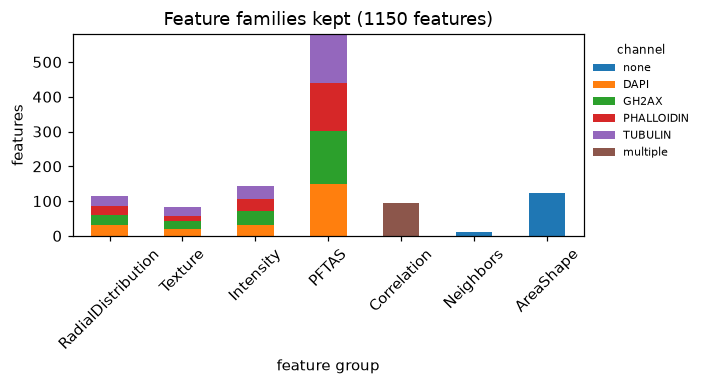

In [5]:
print("degenerate:", int(adata.var["degenerate_scale"].sum()), "of", adata.n_vars)
mt.pp.feature_select(adata)
adata = mt.pp.subset_features(adata)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
mt.pl.feature_groups(adata, ax=ax)
ax.set_title(f"Feature families kept ({adata.n_vars} features)")
fig.tight_layout()
plt.show()

## Is there a plate or well effect left?

Normalizing each well against its own non-targeting cells removes offsets between wells. Whether anything remains is
a question for the controls: a covariate that still explained the control variation would need a batch correction
such as {func}`~mantispy.pp.sphere`. The test compares each covariate against a shuffled copy of itself: if the real
plate labels explain no more than shuffled labels, there is nothing left to remove.

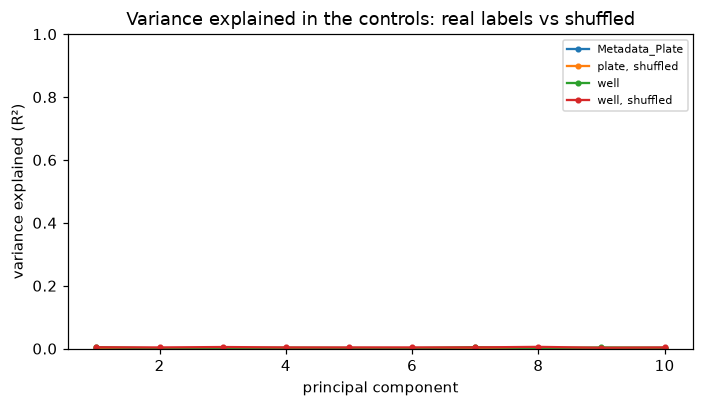

In [6]:
ctrl = adata[(adata.obs["Metadata_Control_Type"] == "negcon").to_numpy()].copy()
ctrl.X = np.nan_to_num(ctrl.X)
sc.pp.pca(ctrl, n_comps=10, random_state=SEED)
rng = np.random.default_rng(SEED)
ctrl.obs["well"] = ctrl.obs["Metadata_Plate"].astype(str) + "_" + ctrl.obs["Metadata_Well"].astype(str)
ctrl.obs["plate, shuffled"] = rng.permutation(ctrl.obs["Metadata_Plate"].to_numpy())
ctrl.obs["well, shuffled"] = rng.permutation(ctrl.obs["well"].to_numpy())
fig, ax = plt.subplots(figsize=(6.5, 3.8))
mt.pl.batch_variance(ctrl, keys=["Metadata_Plate", "plate, shuffled", "well", "well, shuffled"], use_rep="X_pca", ax=ax)
ax.set_title("Variance explained in the controls: real labels vs shuffled")
fig.tight_layout()
plt.show()

Plate and well explain no more of the control variation than shuffled labels do, so no further batch correction is
applied.

## Profiles must be built from comparable numbers of cells

A profile is a median of cells, and its noise falls with the number of cells behind it. If the controls were built
from more cells than the targeting guides, every targeting guide would look more active than the controls merely for
being noisier. Plotting a profile's noise against its cell count, split by control and targeting, shows whether the
matching held.

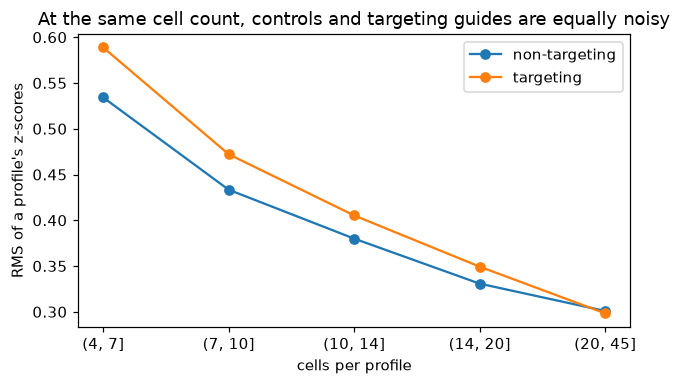

In [7]:
spread = np.sqrt(np.nanmean(np.asarray(adata.X) ** 2, axis=1))
noise = pd.DataFrame(
    {
        "cells": adata.obs["Metadata_CellCount"].to_numpy(),
        "spread": spread,
        "kind": np.where(adata.obs["Metadata_Control_Type"] == "negcon", "non-targeting", "targeting"),
    }
)
noise["bin"] = pd.cut(noise["cells"], [4, 7, 10, 14, 20, 45])
summary = noise.groupby(["bin", "kind"], observed=True)["spread"].median().unstack()
fig, ax = plt.subplots(figsize=(6, 3.6))
for kind in summary.columns:
    ax.plot([str(i) for i in summary.index], summary[kind], marker="o", label=kind)
ax.set_xlabel("cells per profile")
ax.set_ylabel("RMS of a profile's z-scores")
ax.set_title("At the same cell count, controls and targeting guides are equally noisy")
ax.legend()
fig.tight_layout()
plt.show()

At the same cell count, control and targeting profiles are equally noisy. The extraction behind this dataset first
drew twice as many cells per control guide; with that mismatch, every random gene in the library was called a hit.

## From guides to genes

A gene is targeted by four guides, and its call should pool them. Each guide's profiles across the 46 wells are
first combined into one consensus profile. The non-targeting guides then play three separate roles, split at random:

- **scale** (100 guides): {func}`~mantispy.tl.guide_activity` measures every guide against their spread,
- **null** (102 guides): {func}`~mantispy.tl.aggregate_guides` calibrates each gene against random groups of four of them,
- **pseudo-genes** (12 groups of 4): scored like genes, they show how often the procedure calls a gene that does nothing.

Using the same guides for the scale and the null would score the null against itself.

In [8]:
guides = mt.tl.aggregate(adata, by=("Metadata_Guide",), func="median", min_cells=1)
go = guides.obs
ntc = np.sort(go.loc[go["Metadata_Control_Type"] == "negcon", "Metadata_Guide"].astype(str).unique())
roll = np.random.default_rng(SEED).permutation(ntc)
role = dict.fromkeys(roll[:100], "ntc_scale") | dict.fromkeys(roll[100:200], "nontargeting")
role |= {guide: f"PSEUDO{i // 4:02d}" for i, guide in enumerate(roll[200:248])}
assigned = go["Metadata_Guide"].astype(str).map(role)
go["Analysis_Group"] = np.where(assigned.notna(), assigned, go["Metadata_Gene"].astype(str))

## Known pathways already cluster

Before any statistics, an embedding of the guides shows whether the profiles carry real biology. Each point is one
guide in the space of its 50 principal components; nearby guides have similar morphology. The known strong and weak
hits sit apart from the non-targeting cloud, and the positive controls further still.

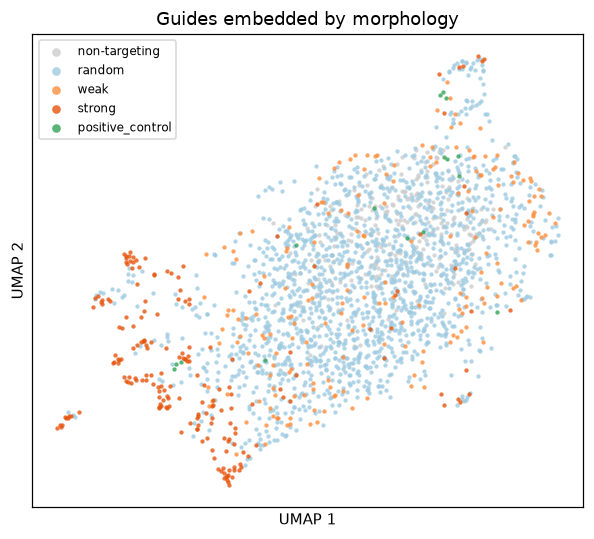

In [9]:
guides.X = np.nan_to_num(guides.X)
sc.pp.pca(guides, n_comps=50, random_state=SEED)
sc.pp.neighbors(guides, use_rep="X_pca", random_state=SEED)
sc.tl.umap(guides, random_state=SEED)
guides.obs["tier"] = np.where(
    guides.obs["Metadata_Control_Type"] == "negcon", "non-targeting", guides.obs["Metadata_Tier"].astype(str)
)
emb = guides.obsm["X_umap"]
fig, ax = plt.subplots(figsize=(5.5, 5))
palette = {
    "non-targeting": "0.8",
    "random": "#9ecae1",
    "weak": "#fd8d3c",
    "strong": "#e6550d",
    "positive_control": "#31a354",
}
for tier in ["non-targeting", "random", "weak", "strong", "positive_control"]:
    m = (guides.obs["tier"] == tier).to_numpy()
    ax.scatter(emb[m, 0], emb[m, 1], s=8, c=palette.get(tier, "0.5"), label=tier, alpha=0.8, linewidths=0)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("Guides embedded by morphology")
ax.legend(markerscale=2, fontsize=8, loc="best")
fig.tight_layout()
plt.show()

## The calibration must be tested on held-out controls

Activity is measured on 50 principal components, fitted on every guide without labels. Fitting them on the scale
guides alone would be a mistake that is easy to make: 50 components fitted to 100 guides describe those guides' own
noise, so in that space every other guide looks quieter than them, and held-out controls get p-values of one. The
check is simple: the held-out pseudo-gene guides should receive uniform p-values, a straight line against the
diagonal.

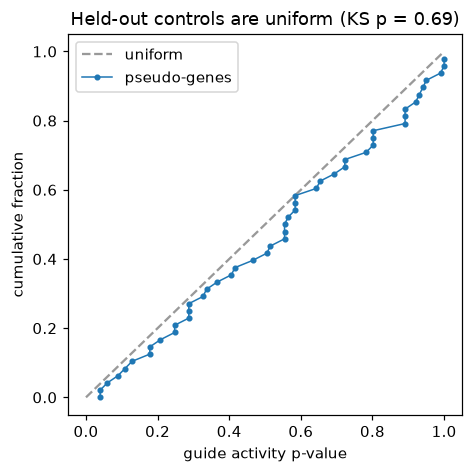

In [10]:
mt.tl.guide_activity(guides, reference="ntc_scale", group="Analysis_Group", use_rep="X_pca")
pseudo = guides.obs["Analysis_Group"].str.startswith("PSEUDO").to_numpy()
p = np.sort(guides.obs.loc[pseudo, "guide_activity"].to_numpy())
fig, ax = plt.subplots(figsize=(4.4, 4.4))
ax.plot([0, 1], [0, 1], "--", color="0.6", label="uniform")
ax.plot(p, np.linspace(0, 1, len(p), endpoint=False), marker=".", lw=1, label="pseudo-genes")
ax.set_xlabel("guide activity p-value")
ax.set_ylabel("cumulative fraction")
ax.set_title(f"Held-out controls are uniform (KS p = {kstest(p, 'uniform').pvalue:.2f})")
ax.legend()
fig.tight_layout()
plt.show()

The held-out controls land on the diagonal, so the scale is honest. Now the genes.

In [11]:
mt.tl.aggregate_guides(
    guides, score="guide_activity", guide="Metadata_Guide", gene="Analysis_Group", control="nontargeting", seed=SEED
)
calls = pd.DataFrame(guides.uns["mantispy"]["gene_aggregation"]).set_index("group").rename_axis("gene")
tier = dict(zip(go["Metadata_Gene"].astype(str), go["Metadata_Tier"].astype(str), strict=True))
calls["tier"] = ["pseudo-gene" if g.startswith("PSEUDO") else tier.get(g, "?") for g in calls.index]

## Cas9 cutting is a phenotype of its own

A targeting guide makes Cas9 cut the genome; a non-targeting guide does not. The double-strand break alone raises
gamma-H2AX, whatever gene is cut. Genes from multi-copy families cut at several loci at once and carry more damage
still. The cells make this visible: compared with a single-copy knockout, a multi-copy cutter lights up the gamma-H2AX
channel.

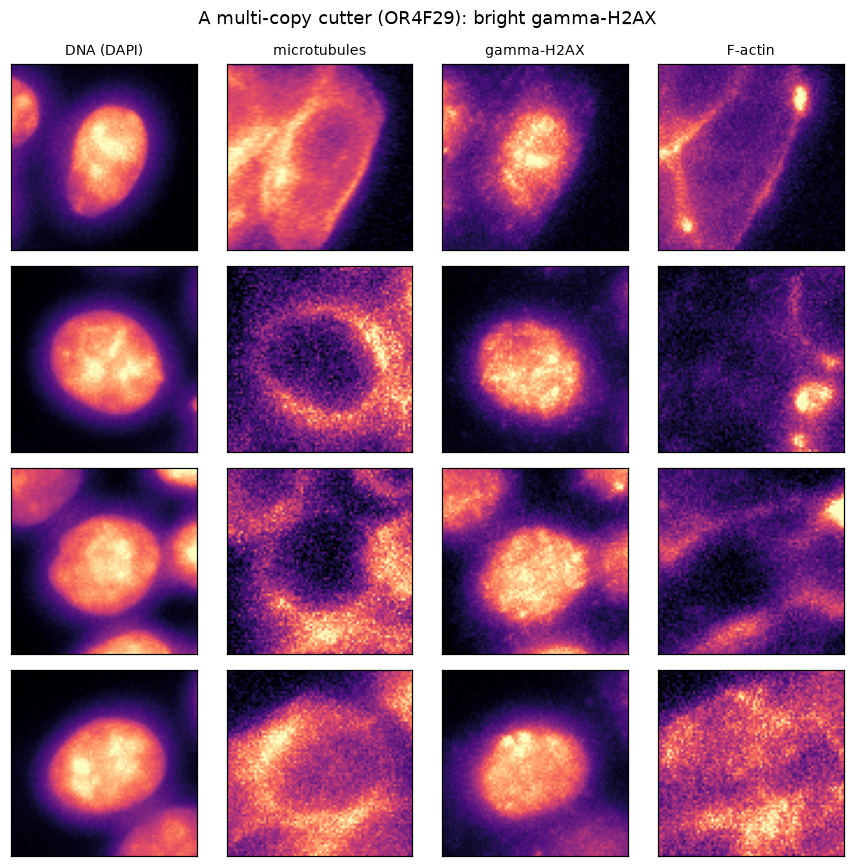

In [12]:
show_cells(example_cells("OR4F29"), "A multi-copy cutter (OR4F29): bright gamma-H2AX")

Genes the cells do not express are the cleanest test of the cut: knocking them out can do nothing, so whatever they
show is the break itself. DepMap's expression for HeLa (model ACH-001086) names them.

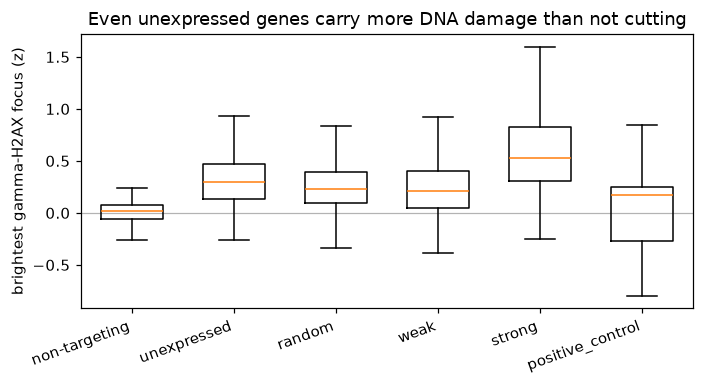

In [13]:
# DepMap 24Q4 expression (CC BY 4.0), fetched from figshare; HeLa is model ACH-001086.
depmap = pooch.retrieve(
    "https://ndownloader.figshare.com/files/51065489",
    known_hash="sha256:2a71dc94110efcc0221eae821bb93a9f03b54bea16f005818911a09d33383d56",
    fname="depmap_24q4_expression.csv",
)
unexpressed = mt.io.unexpressed_genes(depmap, "ACH-001086")
calls["unexpressed"] = calls.index.isin(unexpressed)

foci = "Nuclei_Intensity_MaxIntensity_GH2AX"
kind = np.where(
    go["Metadata_Control_Type"] == "negcon",
    "non-targeting",
    np.where(go["Metadata_Gene"].astype(str).isin(unexpressed), "unexpressed", go["Metadata_Tier"].astype(str)),
)
damage = pd.DataFrame({"z": guides[:, foci].X.ravel(), "kind": kind})
groups = ["non-targeting", "unexpressed", "random", "weak", "strong", "positive_control"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.boxplot([damage.loc[damage["kind"] == g, "z"] for g in groups], tick_labels=groups, showfliers=False, widths=0.6)
ax.axhline(0, color="0.7", lw=0.8, zorder=0)
ax.set_ylabel("brightest gamma-H2AX focus (z)")
ax.set_title("Even unexpressed genes carry more DNA damage than not cutting")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
plt.show()

Guides against genes HeLa does not even express already carry more DNA damage than non-targeting guides. So the
non-targeting null answers *does this guide differ from not cutting*. The question a screen asks is *does losing this
gene do anything beyond the cut*, and the unexpressed genes are its null.
{func}`~mantispy.tl.empirical_fdr` calibrates each gene's combined statistic against them.

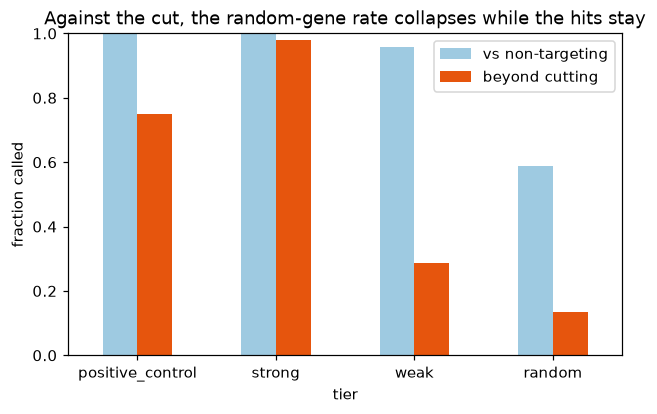

In [14]:
genes = calls[calls["tier"] != "pseudo-gene"].copy()
table = ad.AnnData(obs=pd.DataFrame({"gene": genes.index, "score": genes["statistic"].to_numpy()}, index=genes.index))
mt.tl.empirical_fdr(
    table, control_genes=sorted(set(genes.index) & unexpressed), score="score", group="gene", alpha=0.05, criterion="q"
)
beyond = pd.DataFrame(table.uns["mantispy"]["empirical_fdr"]).set_index("group")
genes["beyond_cutting"] = beyond["is_hit"].reindex(genes.index).astype("boolean")
tested = genes[~genes["unexpressed"]]
rates = tested.groupby("tier").agg(
    **{"vs non-targeting": ("is_hit", "mean"), "beyond cutting": ("beyond_cutting", "mean")}
)
rates = rates.reindex(["positive_control", "strong", "weak", "random"]).dropna(how="all")
ax = rates.plot.bar(figsize=(6.5, 3.8), color=["#9ecae1", "#e6550d"], rot=0)
ax.set_ylabel("fraction called")
ax.set_ylim(0, 1)
ax.set_title("Against the cut, the random-gene rate collapses while the hits stay")
ax.legend()
plt.show()

Against the unexpressed genes, the strong known hits stay (about 98 %) while the random-gene rate falls from about
60 % to about 13 %. With only about 30 unexpressed genes in this subset the null is coarse: the smallest attainable
empirical p-value is about 1/33, which is why the cutoff is a q-value of 0.05.

## Mitosis is reported, not removed

Knockouts that arrest cells in mitosis also shift the pooled profile, because mitotic cells look different. Removing
that effect, or profiling interphase cells only, changes the calls very little here, and the activity of a gene is
nearly independent of its mitotic fraction. The mitotic fraction is best read beside each hit as its own phenotype.

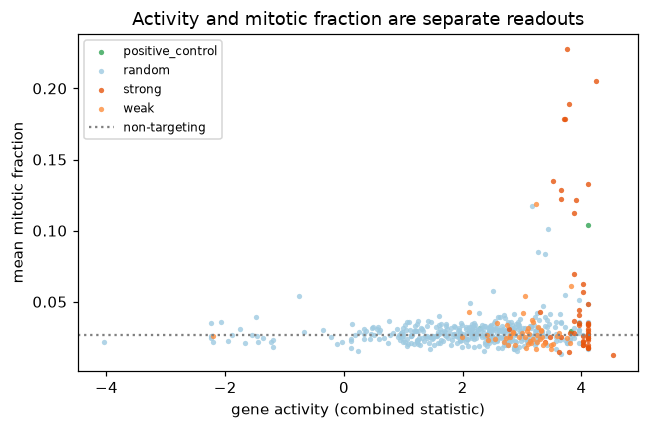

In [15]:
mitotic = adata.obs.groupby("Metadata_Gene", observed=True)["Metadata_MitoticFraction"].mean()
genes["mitotic_fraction"] = mitotic.reindex(genes.index)
palette = {"positive_control": "#31a354", "strong": "#e6550d", "weak": "#fd8d3c", "random": "#9ecae1"}
fig, ax = plt.subplots(figsize=(6, 4))
for tier, sub in genes.groupby("tier"):
    ax.scatter(
        sub["statistic"], sub["mitotic_fraction"], s=12, c=palette.get(tier, "0.6"), label=tier, alpha=0.8, linewidths=0
    )
base = float(mitotic.get("nontargeting", np.nan))
ax.axhline(base, color="0.5", ls=":", label="non-targeting")
ax.set_xlabel("gene activity (combined statistic)")
ax.set_ylabel("mean mitotic fraction")
ax.set_title("Activity and mitotic fraction are separate readouts")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Which channels moved

A hit call says that a gene does something; the features say what. A moderated t-test per feature against the
non-targeting controls ({func}`~mantispy.tl.differential_features`, wells as replicates) collapsed into a signature
per channel and compartment ({func}`~mantispy.tl.feature_signature`) gives a compact fingerprint for each gene.

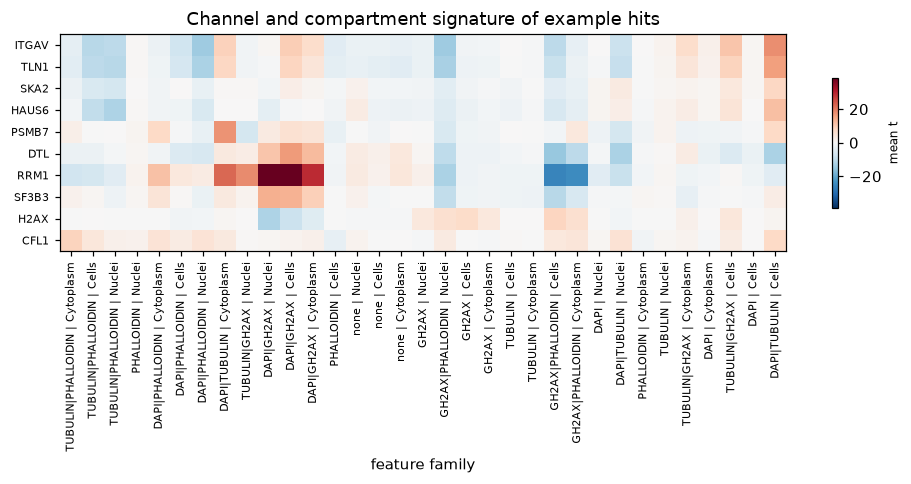

In [16]:
examples = ["RRM1", "DTL", "SKA2", "HAUS6", "ITGAV", "TLN1", "PSMB7", "SF3B3", "H2AX", "CFL1"]
present = [g for g in examples if (adata.obs["Metadata_Gene"].astype(str) == g).any()]
sub = adata[
    adata.obs["Metadata_Gene"]
    .astype(str)
    .isin(
        present
        + list(adata.obs.loc[adata.obs["Metadata_Control_Type"] == "negcon", "Metadata_Gene"].astype(str).unique())
    )
].copy()
mt.tl.differential_features(sub, groupby="Metadata_Gene", reference="negcon", block="Metadata_Plate")
sig = mt.tl.feature_signature(sub, key="differential", by=("channel", "object"), statistic="t")
sig = sig[[g for g in present if g in sig.obs_names]].copy()
fig, ax = plt.subplots(figsize=(9, 4.5))
mt.pl.feature_signature(sig, top=sig.n_vars, ax=ax)
ax.set_title("Channel and compartment signature of example hits")
fig.tight_layout()
plt.show()

Replication-stress genes (RRM1, DTL) light up gamma-H2AX and DNA, the spindle genes (SKA2, HAUS6) tubulin, and the
adhesion genes (ITGAV, TLN1) actin and shape. The fingerprint is what turns a hit into a hypothesis.

## Comparison with the published calls

Brieflow publishes, for each gene, a bootstrap p-value per feature that resamples cells. Calling a gene when any of
its features passes FDR 0.05 treats every cell as an independent replicate, although cells in one well share that
well's conditions.

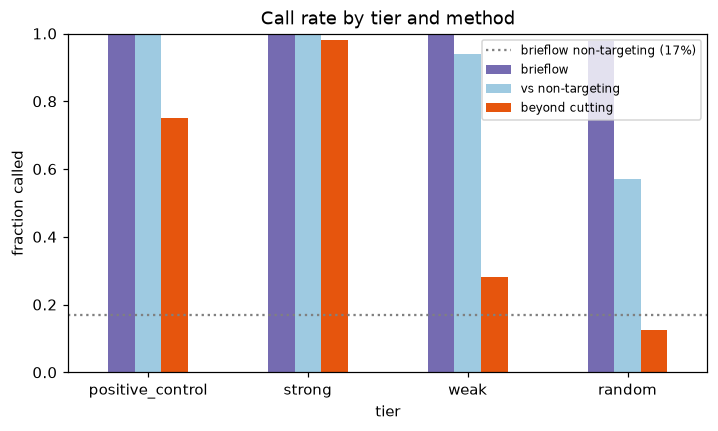

In [17]:
# Brieflow's published interphase gene table, fetched from the OPS Explorer public bucket.
brief = pooch.retrieve(
    "https://ops-explorer-public.s3.amazonaws.com/aconcagua/aconcagua/visualizations/interphase/aggregated_data.h5ad",
    known_hash="sha256:f55756939edc8ddf108092d88c4efe248765b4db4ec39322d4b4a988e04af929",
    fname="brief_interphase.h5ad",
)
published = ad.read_h5ad(brief)
threshold = published.uns["neg_log10_fdr_threshold"]
any_feature = pd.Series((published.layers["neg_log10_fdr"] > threshold).any(axis=1), index=published.obs_names)
ntc_rate = any_feature[any_feature.index.str.startswith("nontargeting")].mean()
compare = genes.join(any_feature.rename("brieflow"), how="inner")
rates = compare.groupby("tier").agg(
    **{
        "brieflow": ("brieflow", "mean"),
        "vs non-targeting": ("is_hit", "mean"),
        "beyond cutting": ("beyond_cutting", "mean"),
    }
)
rates = rates.reindex(["positive_control", "strong", "weak", "random"]).dropna(how="all")
ax = rates.plot.bar(figsize=(7.5, 4), color=["#756bb1", "#9ecae1", "#e6550d"], rot=0)
ax.axhline(ntc_rate, color="0.5", ls=":", label=f"brieflow non-targeting ({ntc_rate:.0%})")
ax.set_ylabel("fraction called")
ax.set_ylim(0, 1)
ax.set_title("Call rate by tier and method")
ax.legend(fontsize=8)
plt.show()

The strong and weak tiers were chosen from brieflow's own effect sizes, so brieflow recovering them is true by
construction and says nothing about either method. The fair comparisons are the controls and the random genes:
brieflow calls about 17 % of its non-targeting guides and almost every random gene, including the unexpressed ones.
With the well as the replicate and the cut accounted for, about one random gene in eight remains. The two approaches
agree on the strong hits; they differ in what they count as evidence.

## Does the screen reproduce?

A call means little if a gene's own guides disagree. {func}`~mantispy.tl.percent_replicating` asks how often the
guides of a gene correlate more than unrelated guides do, against a permutation null, and {func}`~mantispy.tl.grit`
scores how far each guide departs from the controls in units of control spread.

genes whose guides replicate: 56% of 501


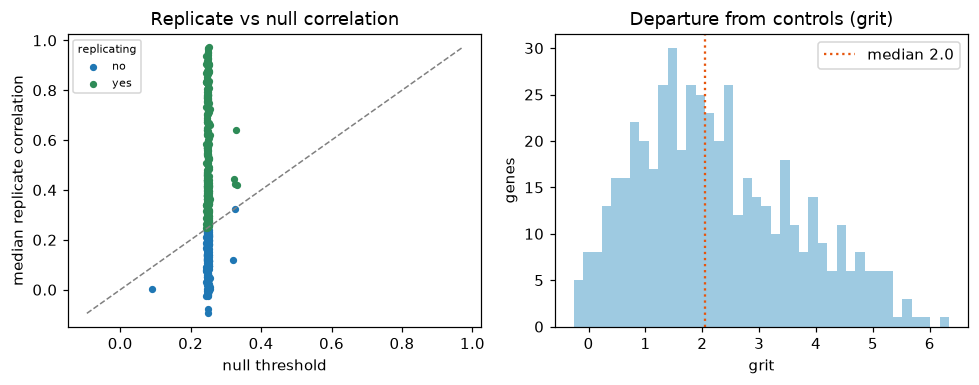

In [18]:
mt.tl.percent_replicating(guides, groupby="Metadata_Gene")
summary = pd.Series(guides.uns["mantispy"]["percent_replicating_summary"])
mt.tl.grit(guides, groupby="Metadata_Gene", reference="negcon")
grit = pd.DataFrame(guides.uns["mantispy"]["grit"])
print(f"genes whose guides replicate: {summary['fraction_replicating']:.0%} of {int(summary['n_groups'])}")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
mt.pl.replicate_correlation(guides, ax=axes[0])
axes[0].set_title("Replicate vs null correlation")
axes[1].hist(grit["grit"].dropna(), bins=40, color="#9ecae1")
axes[1].axvline(float(grit["grit"].median()), color="#e6550d", ls=":", label=f"median {grit['grit'].median():.1f}")
axes[1].set_xlabel("grit")
axes[1].set_ylabel("genes")
axes[1].set_title("Departure from controls (grit)")
axes[1].legend()
fig.tight_layout()
plt.show()

## Inside the well: cells are not identical

A profile is a median over a well's cells, but a knockout rarely moves every cell the same way. The published
subset keeps the single cells for a handful of genes, so the aggregation can be opened up. These cells carry raw
intensities, which is what the cell cycle is read from.

In [19]:
# Single cells for eight genes plus non-targeting controls (raw intensities). Needs igraph + leidenalg to cluster.
cells_file = pooch.retrieve(
    "https://exampledata.scverse.org/mantispy/aconcagua/aconcagua_cells.h5ad",
    known_hash="sha256:fcc65da402b2954d55c1b99bd0b944ed64d8550555ecdfaeb6e42dd7d68eb0ac",
    fname="aconcagua_cells.h5ad",
)
cells = ad.read_h5ad(cells_file)
cells

AnnData object with n_obs × n_vars = 38674 × 1483
    obs: 'Metadata_Plate', 'Metadata_Well', 'Metadata_Site', 'Metadata_ObjectNumber', 'Metadata_Guide', 'Metadata_Gene', 'Metadata_Perturbation', 'Metadata_Control_Type', 'Metadata_Class', 'Metadata_Tier', 'Metadata_Control', 'Metadata_Perturbation_Type', 'Metadata_BarcodeDistance', 'Metadata_MappedBarcodes', 'Metadata_FovDistancePhenotype', 'Metadata_FovDistanceSBS', 'Metadata_ClassConfidence', 'Metadata_TileY', 'Metadata_TileX', 'Metadata_Y', 'Metadata_X', 'Metadata_ImageID', 'Metadata_ObjectType', 'Metadata_Mitotic'
    var: 'object', 'feature_group', 'feature', 'channel', 'scale', 'angle', 'gray_levels', 'radial_bin', 'params', 'is_feature', 'feature_kind'
    uns: 'mantispy'
    layers: None (.X)

Integrated DNA intensity roughly doubles from G1 to G2M, so a two-component fit on it assigns a cell-cycle phase
({func}`~mantispy.tl.cell_cycle_phase`). The spindle genes stall cells before division: their knockouts carry a
far larger share of cells in G2M than the non-targeting controls.

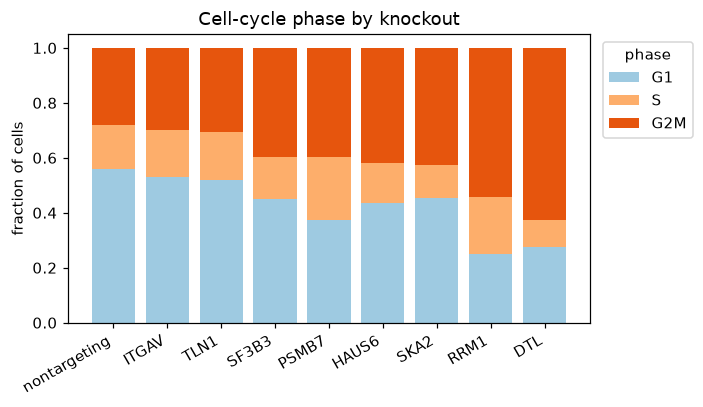

In [20]:
mt.tl.cell_cycle_phase(cells, dna_feature="Nuclei_Intensity_IntegratedIntensity_DAPI", by="Metadata_Plate")
phase = pd.crosstab(cells.obs["Metadata_Gene"], cells.obs["Metadata_CellCyclePhase"], normalize="index")
phase = phase[["G1", "S", "G2M"]].sort_values("G2M")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
bottom = np.zeros(len(phase))
for col, color in zip(["G1", "S", "G2M"], ["#9ecae1", "#fdae6b", "#e6550d"], strict=True):
    ax.bar(phase.index, phase[col], bottom=bottom, color=color, label=col)
    bottom += phase[col].to_numpy()
ax.set_ylabel("fraction of cells")
ax.set_title("Cell-cycle phase by knockout")
ax.legend(title="phase", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
plt.show()

A shift in phase is one kind of heterogeneity. The general question is whether a knockout acts on a particular cell
state. Clustering the single cells and then testing, within each cluster, whether a gene's cells differ from the
controls ({func}`~mantispy.tl.subpopulation_hits`) finds effects that a whole-well median would dilute.

gene-by-cluster subpopulation effects at q < 0.05: 161 of 206


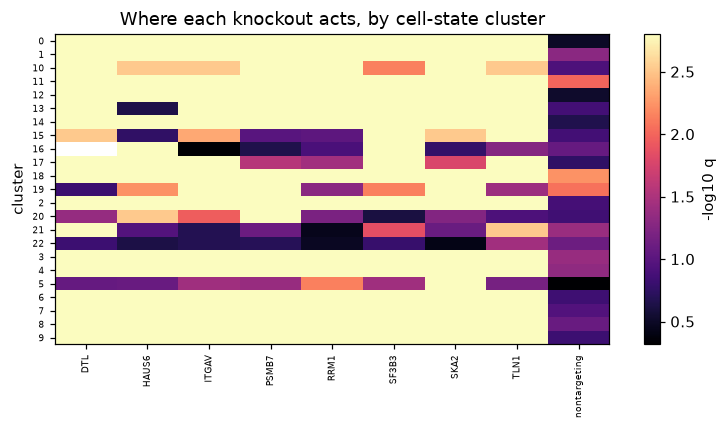

In [21]:
mt.pp.normalize(cells, by=["Metadata_Plate", "Metadata_Well"], reference="negcon")
mt.pp.feature_select(cells)
cells = mt.pp.subset_features(cells)
cells.X = np.nan_to_num(cells.X)
sc.pp.pca(cells, n_comps=30, svd_solver="randomized", random_state=SEED)
sc.pp.neighbors(cells, random_state=SEED)
sc.tl.leiden(cells, random_state=SEED, flavor="igraph", n_iterations=2, directed=False)
mt.tl.subpopulation_hits(cells, groupby="Metadata_Gene", use_rep="X_pca")
sh = pd.DataFrame(cells.uns["mantispy"]["subpopulation_hits"])
print(f"gene-by-cluster subpopulation effects at q < 0.05: {int((sh['qvalue'] < 0.05).sum())} of {len(sh)}")
fig, ax = plt.subplots(figsize=(7, 4))
mt.pl.subpopulation_hits(cells, ax=ax)
ax.set_title("Where each knockout acts, by cell-state cluster")
fig.tight_layout()
plt.show()

Most knockouts register in one or a few of the single-cell clusters, not uniformly across them. The median profile
used for calling is a summary; the cells underneath it carry the structure.

# The phenotypic landscape

The subset was a worked example of calling hits honestly. The reason to run a screen this size is the map it draws:
with every one of the 5,299 genes measured in the same four channels, genes that do similar jobs in the cell end up
looking alike. The published gene-level profiles carry the whole landscape, so the rest of this page works from them.

The claim to test is the one every optical pooled screen rests on: that morphological similarity tracks shared
function. Protein complexes are the sharpest test, because their subunits act as one machine, so knocking out any
member should give the same phenotype.

In [22]:
land = ad.AnnData(
    X=np.nan_to_num(np.asarray(published.X, dtype="float32")),
    obs=pd.DataFrame(
        {
            "Metadata_Gene": published.obs_names.astype(str),
            "cluster": published.obs["cluster_group_1"].astype(str).values,
        },
        index=published.obs_names.astype(str),
    ),
    var=published.var.copy(),
)
land.obsm["X_phate"] = np.asarray(published.obsm["X_phate"])
mt.tl.similarity(land, metric="pearson")  # gene x gene correlation in land.obsp["similarity"]
land

AnnData object with n_obs × n_vars = 5299 × 76
    obs: 'Metadata_Gene', 'cluster'
    var: 'feature_name', 'feature_type', 'compartment'
    uns: 'mantispy'
    obsm: 'X_phate'
    obsp: 'similarity'
    layers: None (.X)

## Complex recovery, measured

{func}`~mantispy.tl.pathway_coherence` turns the claim into a measurement: for each CORUM complex it compares the mean
similarity among its members against random gene groups of the same size, and reports the gap as a coherence with a
permutation p-value. This is the benchmark optical pooled screens are judged by.

CORUM complexes with 4+ members measured: 292; coherent at q < 0.05: 129


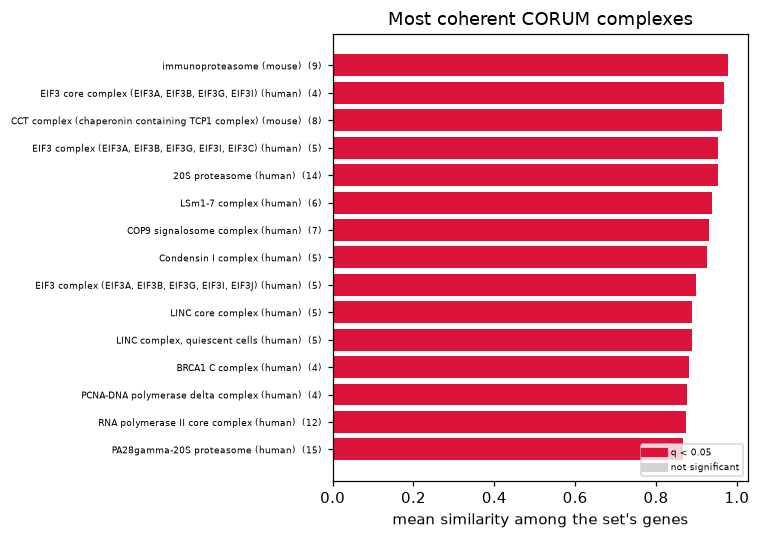

In [23]:
# CORUM protein complexes (Enrichr export), as a source -> target net of complex -> member gene.
corum_gmt = pooch.retrieve(
    "https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName=CORUM",
    known_hash="sha256:b16c8cf235f5fc528f01a5c02aaf3681f74396a3affca5509e98f3ff6d0f2677",
    fname="corum_enrichr.gmt",
)
rows = []
for line in open(corum_gmt):
    parts = line.rstrip("\n").split("\t")
    if len(parts) < 3:
        continue
    for g in parts[2:]:
        g = g.split(",")[0].strip()
        if g:
            rows.append((parts[0], g.upper()))
corum = pd.DataFrame(rows, columns=["source", "target"]).drop_duplicates()
corum["weight"] = 1.0

mt.tl.pathway_coherence(land, corum, gene_key="Metadata_Gene", min_genes=4, n_permutations=1000, seed=SEED)
pc = pd.DataFrame(land.uns["mantispy"]["pathway_coherence"])
print(f"CORUM complexes with 4+ members measured: {len(pc)}; coherent at q < 0.05: {int((pc['qvalue'] < 0.05).sum())}")
fig, ax = plt.subplots(figsize=(7, 5))
mt.pl.pathway_coherence(land, top=15, ax=ax)
ax.set_title("Most coherent CORUM complexes")
fig.tight_layout()
plt.show()

## Genes in the same complex look alike

Ordering the members of the most coherent complexes by membership turns the correlation matrix into blocks: subunits
of one complex correlate with each other far more than with the rest of the screen.

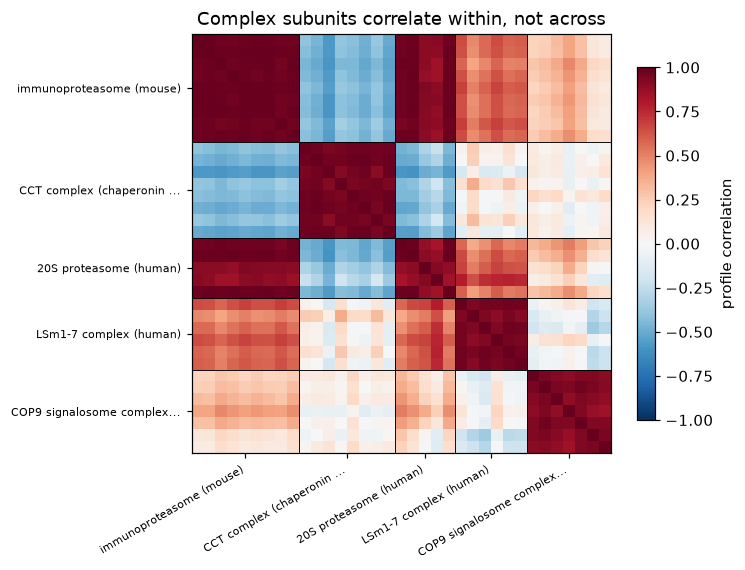

In [24]:
present = set(land.obs_names)
pos = {g: i for i, g in enumerate(land.obs_names)}
top_sets = pc[(pc["n_genes"] >= 6) & (pc["n_genes"] <= 20)].sort_values("coherence", ascending=False)["set"].head(5)
members, bounds, labels = [], [0], []
for cx in top_sets:
    gs = [g for g in sorted(corum.loc[corum["source"] == cx, "target"].unique()) if g in present and g not in members]
    if len(gs) < 4:
        continue
    members += gs
    bounds.append(len(members))
    labels.append(cx if len(cx) < 26 else cx[:24] + "...")
block = land.obsp["similarity"][np.ix_([pos[g] for g in members], [pos[g] for g in members])]
fig, ax = plt.subplots(figsize=(6.8, 5.8))
im = ax.imshow(block, cmap="RdBu_r", vmin=-1, vmax=1)
for b in bounds[1:-1]:
    ax.axhline(b - 0.5, color="k", lw=0.6)
    ax.axvline(b - 0.5, color="k", lw=0.6)
ticks = [(bounds[i] + bounds[i + 1]) / 2 - 0.5 for i in range(len(labels))]
ax.set_xticks(ticks, labels, rotation=30, ha="right", fontsize=7)
ax.set_yticks(ticks, labels, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7, label="profile correlation")
ax.set_title("Complex subunits correlate within, not across")
fig.tight_layout()
plt.show()

Well over a hundred of the measured complexes are coherent beyond chance. The named machines a biologist would expect
sit near the top: the proteasome, the ribosome, the spliceosome. Seen as distributions, their subunits correlate
several times more tightly than random gene pairs.

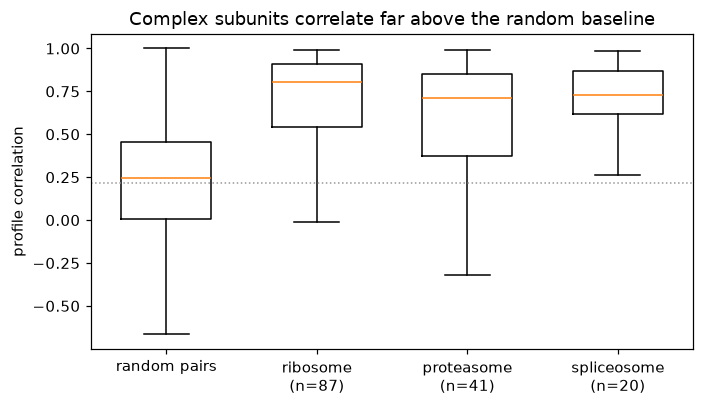

In [25]:
gl = land.obs_names.to_numpy()
pos = {g: i for i, g in enumerate(gl)}
S = land.obsp["similarity"]
rng = np.random.default_rng(SEED)
random_pairs = S[rng.integers(0, S.shape[0], 20000), rng.integers(0, S.shape[0], 20000)]
families = {"ribosome": ("RPL", "RPS"), "proteasome": ("PSM",), "spliceosome": ("SNRP", "SF3")}
data, names = [random_pairs], ["random pairs"]
for name, pref in families.items():
    m = [pos[g] for g in gl if str(g).startswith(pref)]
    sub = S[np.ix_(m, m)]
    data.append(sub[np.triu_indices(len(m), 1)])
    names.append(f"{name}\n(n={len(m)})")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.boxplot(data, tick_labels=names, showfliers=False, widths=0.6)
ax.axhline(float(np.mean(random_pairs)), color="0.6", ls=":", lw=1)
ax.set_ylabel("profile correlation")
ax.set_title("Complex subunits correlate far above the random baseline")
fig.tight_layout()
plt.show()

Not every kind of gene set behaves this way. The broad transcriptional programs of the MSigDB hallmark collection,
which group genes by co-expression rather than by a shared physical machine, are barely coherent in morphology. The
screen sees what cells are built from, not what they transcribe.

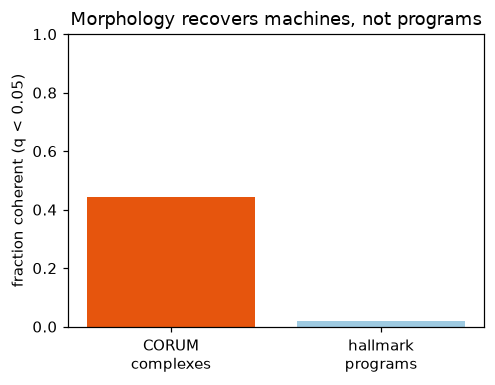

In [26]:
hallmark = mt.tl.gene_sets("hallmark")
mt.tl.pathway_coherence(
    land,
    hallmark,
    gene_key="Metadata_Gene",
    min_genes=5,
    n_permutations=1000,
    seed=SEED,
    key_added="pathway_coherence_hallmark",
)
ph = pd.DataFrame(land.uns["mantispy"]["pathway_coherence_hallmark"])
corum_frac = (pc["qvalue"] < 0.05).mean()
hall_frac = (ph["qvalue"] < 0.05).mean()
fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.bar(["CORUM\ncomplexes", "hallmark\nprograms"], [corum_frac, hall_frac], color=["#e6550d", "#9ecae1"])
ax.set_ylabel("fraction coherent (q < 0.05)")
ax.set_ylim(0, 1)
ax.set_title("Morphology recovers machines, not programs")
fig.tight_layout()
plt.show()

## One number for the claim

Coherence is measured per complex. The claim underneath is a single retrieval question: given two genes, does their
morphological correlation tell a complex co-member from an unrelated pair? Scoring every CORUM co-member pair against
an equal number of random pairs turns that into one curve and one number.

CORUM co-member retrieval: ROC-AUC 0.661, average precision 0.703 (18038 complex pairs)


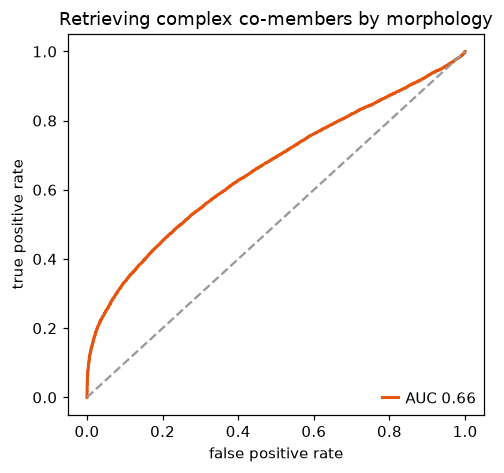

In [27]:
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

pos = {g: i for i, g in enumerate(land.obs_names)}
in_corum = corum[corum["target"].isin(set(land.obs_names))]
comp = {
    c: [pos[g] for g in grp["target"].unique()] for c, grp in in_corum.groupby("source") if grp["target"].nunique() >= 3
}
rng = np.random.default_rng(SEED)
pairs = set()
for members in comp.values():
    for a in range(len(members)):
        for b in range(a + 1, len(members)):
            pairs.add((min(members[a], members[b]), max(members[a], members[b])))
pos_pairs = list(pairs)
rng.shuffle(pos_pairs)
pos_pairs = pos_pairs[:20000]
S = land.obsp["similarity"]
neg = set()
while len(neg) < len(pos_pairs):
    a, b = int(rng.integers(0, S.shape[0])), int(rng.integers(0, S.shape[0]))
    if a != b:
        neg.add((min(a, b), max(a, b)))
neg_pairs = list(neg)[: len(pos_pairs)]
y = np.r_[np.ones(len(pos_pairs)), np.zeros(len(neg_pairs))]
score = np.r_[[S[a, b] for a, b in pos_pairs], [S[a, b] for a, b in neg_pairs]]
auc, ap = roc_auc_score(y, score), average_precision_score(y, score)
fpr, tpr, _ = roc_curve(y, score)
print(f"CORUM co-member retrieval: ROC-AUC {auc:.3f}, average precision {ap:.3f} ({len(pos_pairs)} complex pairs)")
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot(fpr, tpr, color="#e6550d", lw=2, label=f"AUC {auc:.2f}")
ax.plot([0, 1], [0, 1], "--", color="0.6")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("Retrieving complex co-members by morphology")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

Across every CORUM pair the correlation separates co-members from random genes well above chance; the tight physical
machines above sit far higher than this genome-wide average, which mixes them with large, loose complexes.

## The clusters are known machines

The published screen groups the genes into clusters by morphology alone. Testing each large cluster against CORUM
with a hypergeometric test names them: the clusters line up with real complexes and processes, with no knowledge of
sequence or annotation used to build them.

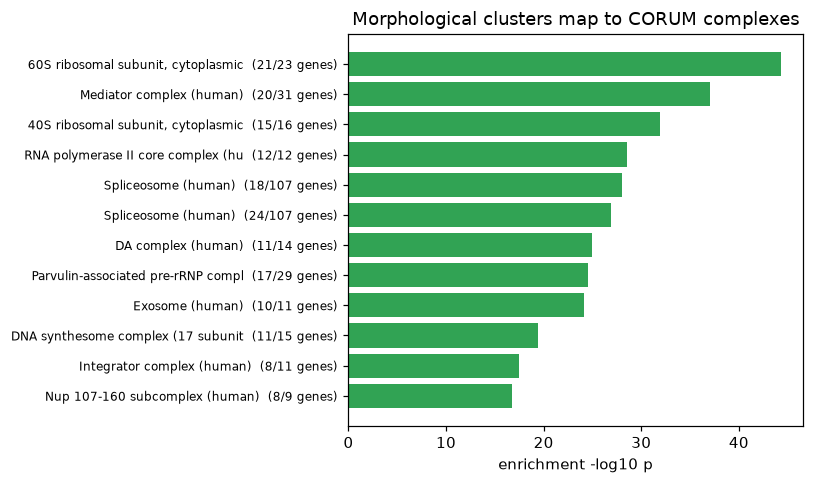

In [28]:
from scipy.stats import hypergeom

n_all = land.n_obs
gene_to_comp = {}
for c, members in comp.items():
    for i in members:
        gene_to_comp.setdefault(i, []).append(c)
rows = []
for cl, size in land.obs["cluster"].value_counts().items():
    if size < 20:
        continue
    members = [pos[g] for g in land.obs_names[(land.obs["cluster"] == cl).to_numpy()]]
    counts = {}
    for i in members:
        for c in gene_to_comp.get(i, []):
            counts[c] = counts.get(c, 0) + 1
    best = None
    for c, k in counts.items():
        if k < 4:
            continue
        p = float(hypergeom.sf(k - 1, n_all, len(comp[c]), len(members)))
        if best is None or p < best[1]:
            best = (c, p, k, len(comp[c]))
    if best and best[1] < 1e-4:
        rows.append((len(members), best[0], best[2], best[3], -np.log10(max(best[1], 1e-300))))
table = pd.DataFrame(rows, columns=["n_genes", "complex", "k", "size", "neglog10p"]).sort_values("neglog10p").tail(12)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
labels = [f"{c[:34]}  ({k}/{s} genes)" for c, k, s in zip(table["complex"], table["k"], table["size"], strict=True)]
ax.barh(range(len(table)), table["neglog10p"], color="#31a354")
ax.set_yticks(range(len(table)), labels, fontsize=8)
ax.set_xlabel("enrichment -log10 p")
ax.set_title("Morphological clusters map to CORUM complexes")
fig.tight_layout()
plt.show()

Clusters built from pixels alone recover named machinery: ribosome biogenesis and rRNA processing, the RNase/MRP
complex, RNA polymerase assemblies. This is the payoff of the landscape. A hit list says which genes matter; the
landscape says what they do, and puts a gene of unknown function in the company of genes whose function is known.

## Where the subset's hits sit

The landscape also places the worked example. Drawing the full screen as its published embedding and marking the
genes the subset called shows them landing in the dense, structured regions of the map, among the complexes, not
scattered through it.

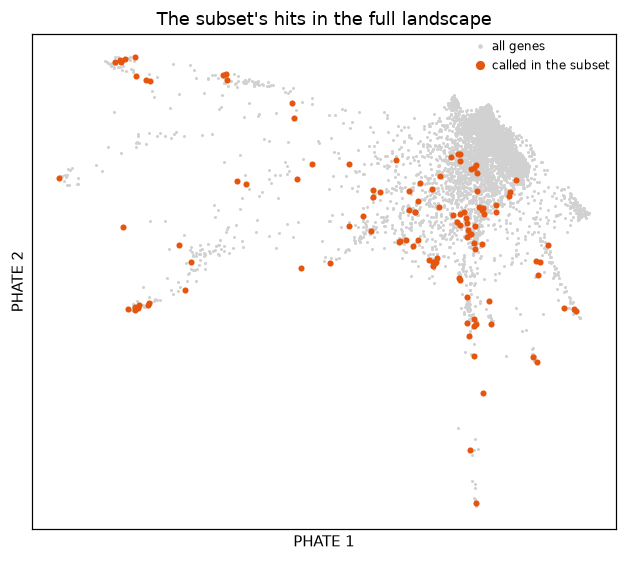

In [29]:
called = set(genes.index[genes["beyond_cutting"].fillna(False).to_numpy()].astype(str))
emb = land.obsm["X_phate"]
mark = np.array([g in called for g in land.obs_names])
fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.scatter(emb[~mark, 0], emb[~mark, 1], s=4, c="0.82", linewidths=0, label="all genes")
ax.scatter(emb[mark, 0], emb[mark, 1], s=16, c="#e6550d", linewidths=0, label="called in the subset")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("PHATE 1")
ax.set_ylabel("PHATE 2")
ax.set_title("The subset's hits in the full landscape")
ax.legend(markerscale=1.5, fontsize=8)
fig.tight_layout()
plt.show()

## What to take away

- In a pooled screen the guide is the unit and the well is the replicate.
- Build control and targeting profiles from comparable numbers of cells.
- Keep the guides that set the scale, form the null and test the calibration separate.
- A non-targeting null measures the effect of cutting; unexpressed genes measure what lies beyond it.
- Report the mitotic fraction beside the hits rather than folding it into them.
- At screen scale, morphological similarity recovers protein complexes: the ribosome, proteasome and spliceosome
  fall out of the correlations, which is the evidence that the phenotypes mean something.